# MSCM-net: Salinas experiments
Runtime must be **GPU** (Runtime → Change runtime type → T4).

Order: Cell 1 → Cell 2 → Cell 3 (download) → Cell 4 (data check) → Cell 5 (baseline) → Cell 6 (augmentation).
After any reconnect, run Cell 1 and Cell 2 again. Finished seeds are saved on Drive and skipped.

## Cell 1: mount Drive and check code files

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os
sys.path.append('/content/drive/MyDrive/MSCMnet/codes')
print(sorted(os.listdir('/content/drive/MyDrive/MSCMnet/codes')))
# expect: experiments.py, hsi_data.py, mscm_modules.py, mscm_net.py, train.py

Mounted at /content/drive
['__pycache__', 'experiments.py', 'figures.py', 'hsi_data.py', 'mscm_modules.py', 'mscm_net.py', 'train.py']


## Cell 2: load code, set Salinas paths

In [2]:
import sys, importlib, glob, torch
import numpy as np
sys.path.append('/content/drive/MyDrive/MSCMnet/codes')
sys.path_importer_cache.clear()

import hsi_data, mscm_modules, mscm_net, train, experiments
for m in (hsi_data, mscm_modules, mscm_net, train, experiments):
    importlib.reload(m)

R = '/content/drive/MyDrive/MSCMnet'
S = f'{R}/data/Salinas'
os.makedirs(S, exist_ok=True)
sal_data, sal_gt = f'{S}/Salinas_corrected.mat', f'{S}/Salinas_gt.mat'

print('GPU available:', torch.cuda.is_available())
print('files present:', os.path.exists(sal_data), os.path.exists(sal_gt))

GPU available: True
files present: False False


## Cell 3: download Salinas into Drive
Colab downloads from Google's servers, so a block on your own connection may not apply. If a file is already on Drive it is skipped.

In [3]:
import urllib.request

def is_mat(path):
    # real MATLAB files start with b'MATLAB'; an error web page starts with '<'
    try:
        with open(path, 'rb') as f:
            return f.read(6) == b'MATLAB'
    except OSError:
        return False

sources = {
    'Salinas_corrected.mat': ['http://www.ehu.eus/ccwintco/uploads/a/a3/Salinas_corrected.mat',
                              'https://www.ehu.eus/ccwintco/uploads/a/a3/Salinas_corrected.mat'],
    'Salinas_gt.mat':        ['http://www.ehu.eus/ccwintco/uploads/f/fa/Salinas_gt.mat',
                              'https://www.ehu.eus/ccwintco/uploads/f/fa/Salinas_gt.mat'],
}

for name, urls in sources.items():
    dest = f'{S}/{name}'
    if is_mat(dest):
        print(name, 'already on Drive'); continue
    for u in urls:
        try:
            req = urllib.request.Request(u, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r, open(dest, 'wb') as f:
                f.write(r.read())
            if is_mat(dest):
                print('downloaded', name, os.path.getsize(dest) // 1024, 'KB'); break
            print('not a MATLAB file from', u); os.remove(dest)
        except Exception as e:
            print('failed', u, '->', repr(e)[:120])
    else:
        print('COULD NOT DOWNLOAD', name, '-> use the fallback cell below')

failed http://www.ehu.eus/ccwintco/uploads/a/a3/Salinas_corrected.mat -> <HTTPError 403: 'Forbidden'>
failed https://www.ehu.eus/ccwintco/uploads/a/a3/Salinas_corrected.mat -> <HTTPError 403: 'Forbidden'>
COULD NOT DOWNLOAD Salinas_corrected.mat -> use the fallback cell below
failed http://www.ehu.eus/ccwintco/uploads/f/fa/Salinas_gt.mat -> <HTTPError 403: 'Forbidden'>
failed https://www.ehu.eus/ccwintco/uploads/f/fa/Salinas_gt.mat -> <HTTPError 403: 'Forbidden'>
COULD NOT DOWNLOAD Salinas_gt.mat -> use the fallback cell below


## Cell 3b (only if Cell 3 failed): look for Salinas on the Hugging Face repo you used before
This only lists matching files. Send me the printed list and I will give you the exact download lines.

In [4]:
from huggingface_hub import HfApi
files = HfApi().list_repo_files('Tanishq165/HSI_Datasets', repo_type='dataset')
print([f for f in files if 'salinas' in f.lower()])
print(len(files), 'files in repo; first 30:', files[:30])

['Salinas/salinas_data.mat', 'Salinas/salinas_gt.mat']
56 files in repo; first 30: ['.gitattributes', 'Augsburg/TestImage.mat', 'Augsburg/TrainImage.mat', 'Augsburg/augsburg_data.mat', 'Augsburg/augsburg_gt.mat', 'Augsburg/data_HS_LR.mat', 'Berlin/TestImage.mat', 'Berlin/TrainImage.mat', 'Berlin/berlin_data.mat', 'Berlin/berlin_gt.mat', 'Berlin/data_HS_LR.mat', 'Botswana/Botswana_data.mat', 'Botswana/Botswana_gt.mat', 'Chikusei/Chikusei_data.mat', 'Chikusei/Chikusei_gt.mat', 'Dioni/dioni_data.mat', 'Dioni/dioni_gt.mat', 'Holden/holden_data.mat', 'Holden/holden_gt.mat', 'Houston13/houston13_data.mat', 'Houston13/houston13_gt.mat', 'Houston18/Houston_data.mat', 'Houston18/Houston_gt.mat', 'Indian_Pines/indian_pines_data.mat', 'Indian_Pines/indian_pines_gt.mat', 'KSC/KSC_data.mat', 'KSC/KSC_gt.mat', 'Loukia/loukia_data.mat', 'Loukia/loukia_gt.mat', 'Muufl/muufl_data.mat']


## Cell 3c (only if everything else failed): upload the two files from your computer
Get them any other way (another network, phone, a mirror), then upload both `.mat` files here.

In [ ]:
from google.colab import files as colab_files
up = colab_files.upload()          # choose Salinas_corrected.mat and Salinas_gt.mat
import shutil
for name in up:
    shutil.move(name, f'{S}/{name}')
print(os.listdir(S))

## Cell 4: check the data against the paper's Table 1

In [6]:
import os
from huggingface_hub import hf_hub_download
from hsi_data import load_hsi
import numpy as np

# Ensure the directory exists
os.makedirs(S, exist_ok=True)

# Download the missing dataset files from Hugging Face if they are not already present
if not os.path.exists(sal_data):
    print("Downloading Salinas_corrected.mat from Hugging Face...")
    hf_hub_download(
        repo_id='Tanishq165/HSI_Datasets',
        repo_type='dataset',
        filename='Salinas/salinas_data.mat',
        local_dir=S,
        local_dir_use_symlinks=False
    )
    os.rename(f"{S}/Salinas/salinas_data.mat", sal_data)
    os.rmdir(f"{S}/Salinas")

if not os.path.exists(sal_gt):
    print("Downloading Salinas_gt.mat from Hugging Face...")
    hf_hub_download(
        repo_id='Tanishq165/HSI_Datasets',
        repo_type='dataset',
        filename='Salinas/salinas_gt.mat',
        local_dir=S,
        local_dir_use_symlinks=False
    )
    os.rename(f"{S}/Salinas/salinas_gt.mat", sal_gt)
    os.rmdir(f"{S}/Salinas")

# Load and verify the data
img, g = load_hsi(sal_data, sal_gt)
print('image', img.shape, ' gt', g.shape)          # expect (512, 217, 204) and (512, 217)
print('classes', np.unique(g))                     # expect 0..16
print('labeled pixels', int((g > 0).sum()))        # expect 54129

expected = [2009, 3726, 1976, 1394, 2678, 3959, 3579, 11271, 6203, 3278, 1068, 1927, 916, 1070, 7268, 1807]
counts = np.bincount(g.ravel())[1:].tolist()
print('class counts match paper Table 1:', counts == expected)
if counts != expected:
    print(counts)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Salinas/salinas_data.mat: reconstructing file:   0%|          |  0.00B / 45.3MB            

Salinas/salinas_data.mat: downloading bytes:           |  0.00B            

Salinas/salinas_gt.mat: reconstructing file:   0%|          |  0.00B /  111kB            

Salinas/salinas_gt.mat: downloading bytes:           |  0.00B            

image (512, 217, 204)  gt (512, 217)
classes [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]
labeled pixels 54129
class counts match paper Table 1: True


## Cell 5: baseline (faithful to the paper, no augmentation), 10 seeds
About 30 to 50 minutes. Keep the tab open.

In [8]:
experiments.run_config('sal_base', sal_data, sal_gt, R, cache_name='salinas')

[sal_base] seed 0 done, skipping
salinas seed=1 device=cuda classes=16 train=480 test=53649 params=578,140
ep   1  loss 2.0362  train_acc 53.5%  [2s]
ep  10  loss 0.0775  train_acc 100.0%  [17s]
ep  20  loss 0.0193  train_acc 100.0%  [34s]
ep  30  loss 0.0089  train_acc 100.0%  [51s]
ep  40  loss 0.0052  train_acc 100.0%  [67s]
ep  50  loss 0.0040  train_acc 100.0%  [84s]
ep  60  loss 0.0029  train_acc 100.0%  [101s]
ep  70  loss 0.0021  train_acc 100.0%  [117s]
ep  80  loss 0.0019  train_acc 100.0%  [134s]
ep  90  loss 0.0015  train_acc 100.0%  [151s]
ep 100  loss 0.0012  train_acc 100.0%  [168s]
RESULT salinas seed=1: OA 93.16  AA 97.49  Kappa 92.39
salinas seed=2 device=cuda classes=16 train=480 test=53649 params=578,140
ep   1  loss 2.0590  train_acc 51.9%  [2s]
ep  10  loss 0.0682  train_acc 100.0%  [17s]
ep  20  loss 0.0179  train_acc 100.0%  [33s]
ep  30  loss 0.0100  train_acc 100.0%  [50s]
ep  40  loss 0.0060  train_acc 100.0%  [67s]
ep  50  loss 0.0042  train_acc 100.0%  [84s

## Cell 6: augmentation, 10 seeds, then paired comparison

In [9]:
experiments.run_config('sal_aug', sal_data, sal_gt, R, cache_name='salinas', augment=True)
experiments.compare(R, 'sal_aug', baseline='sal_base')

salinas seed=0 device=cuda classes=16 train=480 test=53649 params=578,140
ep   1  loss 2.0896  train_acc 46.7%  [2s]
ep  10  loss 0.1240  train_acc 97.5%  [18s]
ep  20  loss 0.0333  train_acc 99.8%  [35s]
ep  30  loss 0.0196  train_acc 99.8%  [52s]
ep  40  loss 0.0093  train_acc 100.0%  [69s]
ep  50  loss 0.0051  train_acc 100.0%  [86s]
ep  60  loss 0.0386  train_acc 99.6%  [103s]
ep  70  loss 0.0045  train_acc 100.0%  [120s]
ep  80  loss 0.0027  train_acc 100.0%  [136s]
ep  90  loss 0.0343  train_acc 98.5%  [153s]
ep 100  loss 0.0023  train_acc 100.0%  [170s]
RESULT salinas seed=0: OA 96.67  AA 98.50  Kappa 96.30
salinas seed=1 device=cuda classes=16 train=480 test=53649 params=578,140
ep   1  loss 2.0393  train_acc 52.9%  [2s]
ep  10  loss 0.1135  train_acc 98.1%  [17s]
ep  20  loss 0.0453  train_acc 98.8%  [34s]
ep  30  loss 0.0139  train_acc 99.8%  [51s]
ep  40  loss 0.0091  train_acc 99.8%  [68s]
ep  50  loss 0.0124  train_acc 99.8%  [85s]
ep  60  loss 0.0189  train_acc 99.8%  [10

## Summary of saved Salinas results (no training)

In [10]:
def summary(tag):
    rs = [np.load(f) for f in sorted(glob.glob(f'{R}/results/{tag}_seed*.npz'))]
    for k in ('OA', 'AA', 'Kappa'):
        v = np.array([float(r[k]) for r in rs])
        print(f'{tag:9s} {k:6s} {v.mean():.2f} ± {v.std():.2f}   (min {v.min():.2f}, max {v.max():.2f}, n={len(v)})')

for tag in ('sal_base', 'sal_aug'):
    if glob.glob(f'{R}/results/{tag}_seed*.npz'):
        summary(tag)
print('paper: OA 98.35  AA 98.99  Kappa 98.16')

sal_base  OA     90.81 ± 2.31   (min 86.31, max 94.03, n=10)
sal_base  AA     96.34 ± 1.10   (min 94.47, max 97.83, n=10)
sal_base  Kappa  89.77 ± 2.58   (min 84.78, max 93.36, n=10)
sal_aug   OA     95.73 ± 1.17   (min 94.00, max 97.25, n=10)
sal_aug   AA     98.22 ± 0.51   (min 97.48, max 98.83, n=10)
sal_aug   Kappa  95.24 ± 1.31   (min 93.34, max 96.94, n=10)
paper: OA 98.35  AA 98.99  Kappa 98.16


In [5]:
import sys, os
from google.colab import drive

# Mount drive in case of a runtime restart
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

code_dir = '/content/drive/MyDrive/MSCMnet/codes'

# Force insert the path to ensure it is at the very front of sys.path
if code_dir in sys.path:
    sys.path.remove(code_dir)
sys.path.insert(0, code_dir)

# Clear import caches
sys.path_importer_cache.clear()

# Quick validation that the directory is valid and accessible
if os.path.exists(code_dir):
    print("Code directory files:", os.listdir(code_dir))
else:
    print("WARNING: code_dir path does not exist!")

import numpy as np, torch
from torch.utils.data import DataLoader
from hsi_data import build
from mscm_net import MSCMNet
from train import evaluate

R = '/content/drive/MyDrive/MSCMnet'
S = f'{R}/data/Salinas'
sal_data, sal_gt = f'{S}/Salinas_corrected.mat', f'{S}/Salinas_gt.mat'

device = 'cuda'
seed = 0
tr, te, g = build(sal_data, sal_gt, n_components=30, patch=15, n_train=30, seed=seed,
                  cache_dir=f'{R}/data/cache', name='salinas')
m = MSCMNet(in_ch=30, num_classes=16).to(device)
m.load_state_dict(torch.load(f'{R}/checkpoints/sal_aug_seed{seed}.pt', map_location=device))
res = evaluate(m, DataLoader(te, batch_size=256), 16, device)

print(np.round(res['per_class'], 1))
cm = res['cm']
for c in (8, 15):
    row = cm[c-1]; top = np.argsort(row)[::-1][:3]
    print(f'true class {c}:', {int(t)+1: int(row[t]) for t in top})

Code directory files: ['__pycache__', 'hsi_data.py', 'mscm_modules.py', 'mscm_net.py', 'experiments.py', 'train.py', 'figures.py']
[100.  100.  100.   99.4  98.  100.  100.   89.2 100.   96.3 100.   99.1
 100.   99.5  95.1  99.4]
true class 8: {8: 10026, 15: 1031, 10: 162}
true class 15: {15: 6881, 8: 357, 14: 0}


using sal_aug seed 8 (OA 95.56; mean over seeds 95.73)
test OA 95.56  AA 98.00  Kappa 95.06


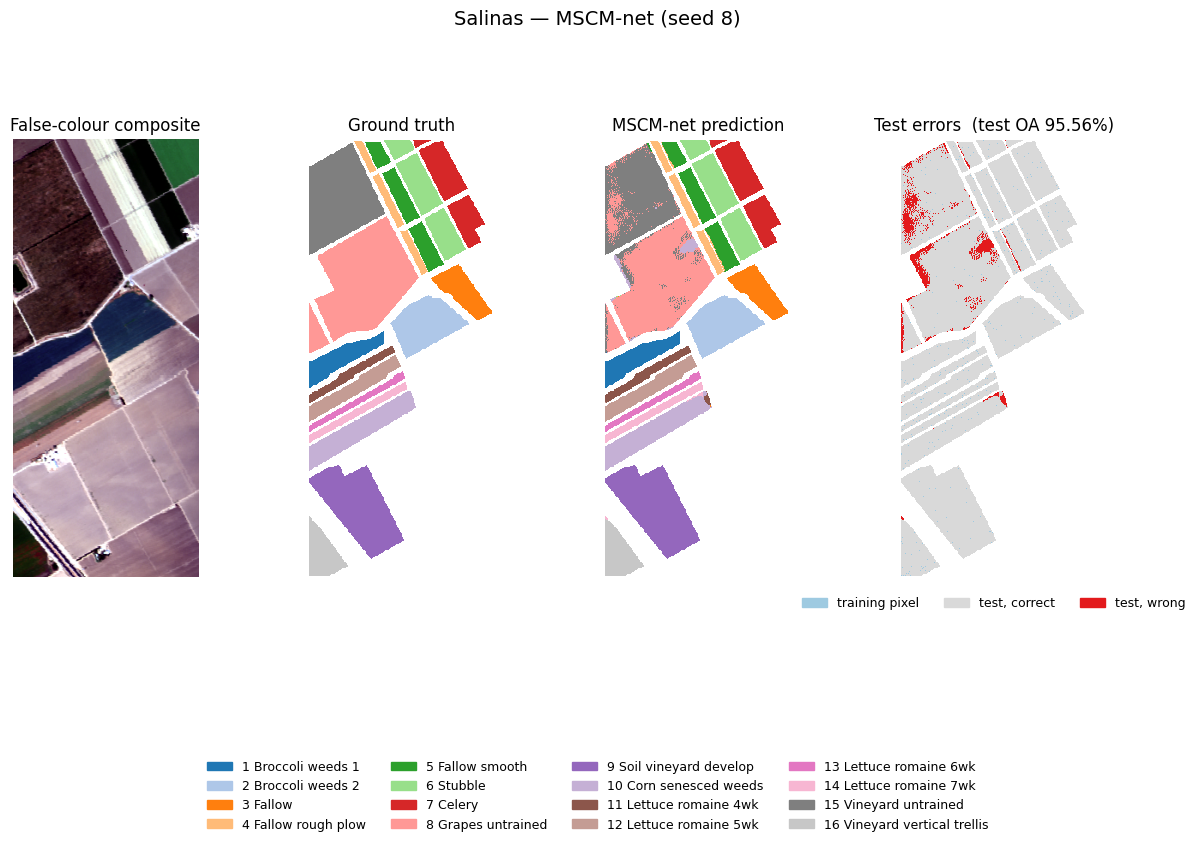

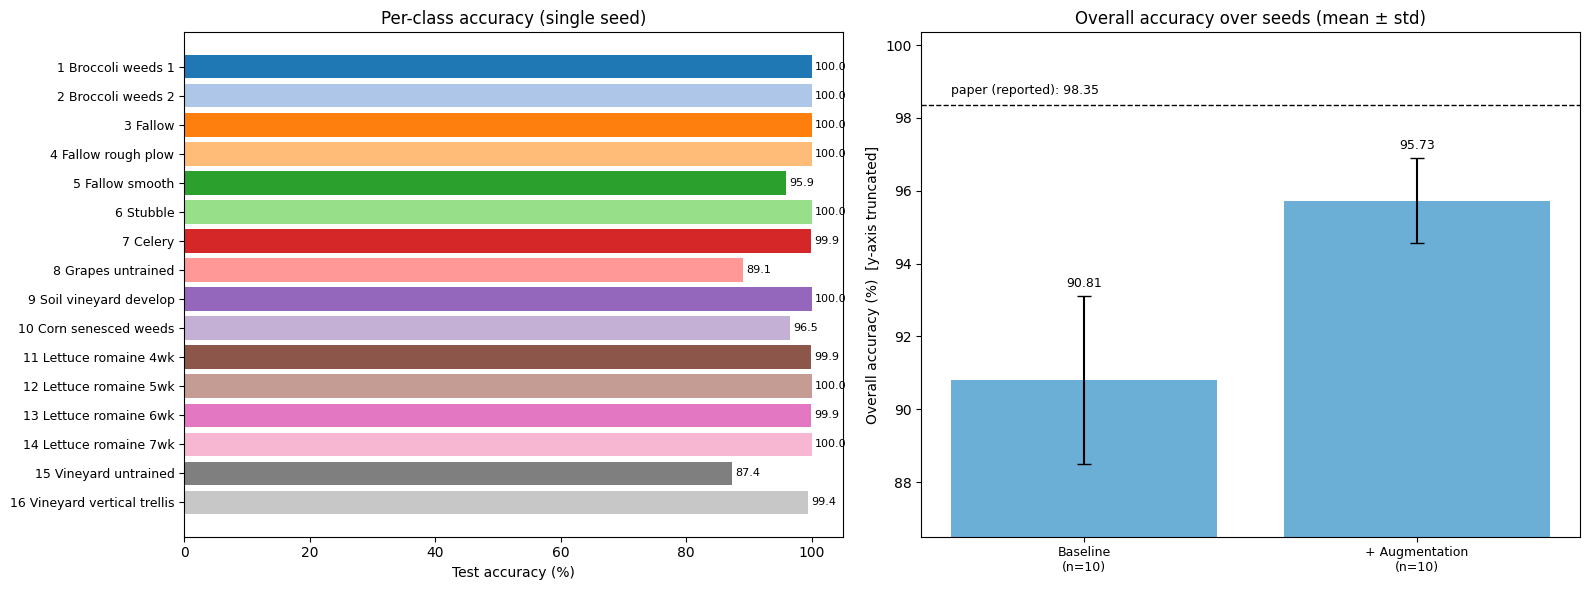

saved to /content/drive/MyDrive/MSCMnet/results/figures


{'OA': np.float64(95.56002907789521),
 'AA': np.float64(97.99717153252465),
 'Kappa': np.float64(95.05916046521642),
 'per_class': array([100.        , 100.        , 100.        , 100.        ,
         95.92145015, 100.        ,  99.85911524,  89.066809  ,
        100.        ,  96.52093596,  99.90366089, 100.        ,
         99.88713318, 100.        ,  87.35838629,  99.4372538 ]),
 'cm': array([[ 1979,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0],
        [    0,  3696,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0],
        [    0,     0,  1946,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0],
        [    0,     0,     0,  1364,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0],
        [    0,     0,     0,   108,  2540,     0,     0,     0,     0,
          

In [7]:
import importlib, figures
importlib.reload(figures)
figures.make_figures(R, sal_data, sal_gt, dataset='salinas')